# Extração e Validação de Precificação de Crédito Privado (Debêntures) — Metodologia ANBIMA / SND

Este caderno documenta a integração de dados e a precificação analítica fluxo a fluxo de instrumentos de crédito privado (debêntures) negociados no mercado secundário brasileiro, seguindo os padrões normativos da Associação Brasileira das Entidades dos Mercados Financeiro e de Capitais (ANBIMA) e do Sistema Nacional de Debêntures (SND).

A modelagem contempla todas as famílias de indexadores vigentes no mercado:
1. **IPCA + Cupom (`VALEA0`):** Reconstituição do $VNA$, juros acruados $T-6$ e desconto por taxa real.
2. **Prefixado (`AEGPA0`):** Cupom prefixado em base `BUS/252` descontado pela taxa indicativa nominal.
3. **DI + Spread (`AALM12`):** Acumulação histórica de CDI via série SGS 12 (BCB), projeção de juros futuros pela curva `PRE` da B3 e desconto composto por `DI + Spread`.
4. **Percentual do DI (`KLBNA2`):** Acumulação e projeção por multiplicador diário sobre a curva `DI`, com amortização percentual fixa sobre o Valor Nominal de Emissão ($VNE$).


In [1]:
import datetime
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from bz_pricing.core.calendars import get_calendar
from bz_pricing.curves.manager import CurveManager
from bz_pricing.data.loaders import B3DataLoader
from bz_pricing.data.debentures import DebenturesClient
from bz_pricing.instruments.credit import Debenture

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.figsize'] = (12, 6)

cal = get_calendar('B3')
base_date = datetime.date(2026, 10, 30)
client = DebenturesClient(data_dir='../dados/debentures')
curve_manager = CurveManager(loader=B3DataLoader(data_dir='../dados/b3'), allow_download=True)
curva_pre = curve_manager.get_curve('PRE', base_date)

print(f"Data-base de análise: {base_date.strftime('%d/%m/%Y')}")
print(f"Diretório de cache local: {client.data_dir}")


Data-base de análise: 30/10/2026
Diretório de cache local: ../dados/debentures


## 1. Panorama Consolidado do Mercado Secundário da ANBIMA (30/10/2026)

Recupera-se o arquivo oficial diário de mercado secundário de debêntures divulgado pela ANBIMA (`db261030.txt`), o qual contém as taxas de compra, venda, taxas indicativas de fechamento, PU de mercado, cotação percentual sobre o PU Par e duration de Macaulay.


In [2]:
# Carrega base oficial da ANBIMA com 1.272 debêntures
df_mkt = client.get_market_prices(base_date)
print(f"Total de debêntures precificadas pela ANBIMA em {base_date.strftime('%d/%m/%Y')}: {len(df_mkt)}")

# Distribuição por família de indexador
df_mkt['familia_indice'] = df_mkt['indice_correcao'].apply(
    lambda x: 'DI + Spread' if 'DI +' in str(x)
    else ('% do DI' if '% DI' in str(x) or '% do DI' in str(x)
    else ('IPCA' if 'IPCA' in str(x)
    else ('IGP-M' if 'IGP' in str(x)
    else ('Prefixado' if 'PRÉ' in str(x).upper() or 'PRE' in str(x).upper()
    else 'Outros'))))
)

print("\nDistribuição de debêntures por família de remuneração:")
print(df_mkt['familia_indice'].value_counts())

display(df_mkt[['codigo', 'nome', 'vencimento', 'indice_correcao', 'taxa_indicativa', 'pu_mercado', 'perc_pu_par', 'duration']].head(5))


Total de debêntures precificadas pela ANBIMA em 30/10/2026: 1272

Distribuição de debêntures por família de remuneração:
familia_indice
IPCA           664
DI + Spread    578
Prefixado       24
% do DI          5
IGP-M            1
Name: count, dtype: int64


,codigo,nome,vencimento,indice_correcao,taxa_indicativa,pu_mercado,perc_pu_par,duration
0,AALM12,AURA ALMAS MINERACAO S.A.,2030-10-02,"DI + 1,6%",0.8877,1025.332013,101.4273,508.56
1,ACOV15,ACO VERDE DO BRASIL S/A,2032-06-10,"DI + 1,1%",1.7452,1042.375579,98.5473,577.74
2,ADPA21,AGUAS DO PARA A SPE S.A.,2027-11-27,"DI + 2,85%",2.8073,1059.942824,100.0415,251.82
3,AEGE16,EQUIPAV SANEAMENTO S.A.,2034-03-11,"DI + 3,9%",6.1122,954.572008,93.3371,814.48
4,AEGE17,EQUIPAV SANEAMENTO S.A.,2035-06-15,"DI + 3,4%",6.9452,940.729757,88.3237,902.71


## 2. Validação de Debênture Indexada ao IPCA: VALE S/A (`VALEA0`)

A série `VALEA0` é uma debênture incentivada (Lei 12.431) emitida pela Vale S/A em 15/10/2024, indexada ao IPCA com taxa semestral de 6,3837% a.a. e vencimento em 15/10/2034.


In [3]:
# Construção automática do instrumento a partir do SND
deb_vale = Debenture.from_ticker('VALEA0', client=client)

print(f"Ativo: {deb_vale.ticker}")
print(f"Indexador: {deb_vale.indexador}")
print(f"Taxa de Cupom Anual: {deb_vale.coupon_rate * 100:.4f}% a.a.")
print(f"Data de Emissão: {deb_vale.issue_date.strftime('%d/%m/%Y')}")
print(f"Data de Vencimento: {deb_vale.maturity_date.strftime('%d/%m/%Y')}")

# Parâmetros oficiais ANBIMA / SND em 30/10/2026
vna_oficial_vale = 1096.791130
pu_par_oficial_vale = 1099.757794
row_vale_mkt = df_mkt[df_mkt['codigo'] == 'VALEA0'].iloc[0]
taxa_ind_vale = row_vale_mkt['taxa_indicativa'] / 100.0
pu_mkt_oficial_vale = row_vale_mkt['pu_mercado']
perc_pu_par_oficial = row_vale_mkt['perc_pu_par']
dur_oficial_vale = row_vale_mkt['duration']

# 1. Validação do PU Par
pu_par_calc = deb_vale.pu_par(base_date, vna=vna_oficial_vale)
diff_par = pu_par_calc - pu_par_oficial_vale
print(f"\n--- PU PAR (SND) ---")
print(f"PU Par Calculado: R$ {pu_par_calc:.6f}")
print(f"PU Par Oficial:   R$ {pu_par_oficial_vale:.6f}")
print(f"Diferença no PU Par: R$ {diff_par:.6f} (Aderência no centavo)")

# 2. Decomposição Fluxo a Fluxo e Marcação a Mercado
pu_mkt_calc, df_cf_vale = deb_vale.present_value(base_date, taxa_ind_vale, vna=vna_oficial_vale, return_cashflows=True)
dur_calc_vale = deb_vale.duration(base_date, taxa_ind_vale, vna=vna_oficial_vale)
cot_calc_vale = deb_vale.cotacao(base_date, taxa_ind_vale, vna=vna_oficial_vale)

print(f"\n--- MARCAÇÃO A MERCADO (ANBIMA) ---")
print(f"Taxa Indicativa ANBIMA: {taxa_ind_vale * 100:.4f}% a.a.")
print(f"PU Mercado Calculado: R$ {pu_mkt_calc:.6f} | Oficial: R$ {pu_mkt_oficial_vale:.6f}")
print(f"Cotação Calculada:    {cot_calc_vale:.4f}% | Oficial: {perc_pu_par_oficial:.4f}%")
print(f"Duration Calculada:   {dur_calc_vale:.2f} DU | Oficial: {dur_oficial_vale:.2f} DU")
risk_vale = deb_vale.risk_metrics(base_date, taxa_ind_vale, vna=vna_oficial_vale)
print(f"Duration Modificada:  {risk_vale['modified_duration']:.4f} anos")
print(f"DV01 (1 bps):         R$ {risk_vale['dv01']:.6f}")
print(f"Convexidade:          {risk_vale['convexity']:.4f} anos^2")

display(df_cf_vale[['data_pagamento', 'du', 'evento', 'fluxo_nominal', 'taxa_desconto', 'fator_desconto', 'valor_presente']])


Ativo: VALEA0
Indexador: IPCA
Taxa de Cupom Anual: 6.3837% a.a.
Data de Emissão: 15/10/2024
Data de Vencimento: 16/10/2034

--- PU PAR (SND) ---
PU Par Calculado: R$ 1099.757794
PU Par Oficial:   R$ 1099.757794
Diferença no PU Par: R$ 0.000000 (Aderência no centavo)

--- MARCAÇÃO A MERCADO (ANBIMA) ---
Taxa Indicativa ANBIMA: 7.6229% a.a.
PU Mercado Calculado: R$ 1022.352694 | Oficial: R$ 1022.352694
Cotação Calculada:    92.9616% | Oficial: 92.9616%
Duration Calculada:   1579.24 DU | Oficial: 1579.24 DU
Duration Modificada:  5.8230 anos
DV01 (1 bps):         R$ 0.595313
Convexidade:          44.6096 anos^2


,data_pagamento,du,evento,fluxo_nominal,taxa_desconto,fator_desconto,valor_presente
0,2027-04-15,112,Juros,33.633296,0.076229,1.033189,32.552891
1,2027-10-15,239,Juros,34.744208,0.076229,1.072158,32.405864
2,2028-04-17,365,Juros,34.466378,0.076229,1.112272,30.987354
3,2028-10-16,490,Juros,34.188615,0.076229,1.153551,29.637708
4,2029-04-16,612,Juros,33.355739,0.076229,1.195316,27.905368
5,2029-10-15,738,Juros,34.466378,0.076229,1.240038,27.794603
6,2030-04-15,861,Juros,33.633296,0.076229,1.285309,26.167470
7,2030-10-15,989,Juros,35.022108,0.076229,1.334176,26.249983
8,2031-04-15,1112,Juros,33.633296,0.076229,1.382884,24.321125
9,2031-10-15,1240,Juros,35.022108,0.076229,1.435461,24.397816


## 3. Validação de Debênture Pós-Fixada DI com Amortizações: AURA ALMAS (`AALM12`)

A série `AALM12` remunera a taxa DI + 1,60% a.a. e possui cronograma com amortizações periódicas a partir de 2027.


In [4]:
deb_aalm = Debenture.from_ticker('AALM12', client=client)
mkt_aalm = df_mkt[df_mkt['codigo'] == 'AALM12'].iloc[0]
taxa_ind_aalm = mkt_aalm['taxa_indicativa'] / 100.0

metrics_aalm = deb_aalm.risk_metrics(base_date, taxa_ind_aalm, vna=deb_aalm.nominal_value, di_curve=curva_pre)
pu_calc_aalm, df_cf_aalm = deb_aalm.present_value(
    base_date, taxa_ind_aalm, vna=deb_aalm.nominal_value, di_curve=curva_pre, return_cashflows=True
)

print(f"Ativo: {deb_aalm.ticker} | Indexador: {deb_aalm.indexador} + {deb_aalm.coupon_rate*100:.2f}% a.a.")
print(f"PU Par Calculado (SGS 12): R$ {metrics_aalm['pu_par']:.6f} | Oficial SND: R$ 1010.903086")
print(f"PU Mercado Calculado:      R$ {metrics_aalm['pu']:.6f} | Oficial ANBIMA: R$ {mkt_aalm['pu_mercado']:.6f} (Dif: {metrics_aalm['pu'] - mkt_aalm['pu_mercado']:+.6f})")
print(f"Cotação (% PU Par):        {metrics_aalm['cotacao']:.4f}% | Oficial ANBIMA: {mkt_aalm['perc_pu_par']:.4f}%")
print(f"Duration Macaulay:         {metrics_aalm['duration_du']:.2f} DU | Oficial ANBIMA: {mkt_aalm['duration']:.2f} DU")
print(f"Duration Modificada:       {metrics_aalm['modified_duration']:.4f} anos | DV01: R$ {metrics_aalm['dv01']:.6f} | Convexidade: {metrics_aalm['convexity']:.2f}")
df_cf_aalm.head(10)


Ativo: AALM12 | Indexador: DI + 1.60% a.a.
PU Par Calculado (SGS 12): R$ 1010.903085 | Oficial SND: R$ 1010.903086
PU Mercado Calculado:      R$ 1025.331425 | Oficial ANBIMA: R$ 1025.332013 (Dif: -0.000588)
Cotação (% PU Par):        101.4272% | Oficial ANBIMA: 101.4273%
Duration Macaulay:         508.54 DU | Oficial ANBIMA: 508.56 DU
Duration Modificada:       1.7398 anos | DV01: R$ 0.178382 | Convexidade: 5.30


,data_evento,data_pagamento,du,evento,tipo,taxa_cupom,fluxo_nominal,taxa_desconto,fator_desconto,valor_presente
0,2027-04-02,2027-04-02,103,Juros,DIDI,0.016,73.057824,0.149066,1.058436,69.024298
1,2027-10-02,2027-10-04,231,Juros,DIDI,0.016,80.687172,0.153394,1.139758,70.793235
2,2027-10-02,2027-10-04,231,Amortização,VNA VAR/UNIFVNA VAR/UNIF,0.000,142.857000,0.153394,1.139758,125.339740
3,2028-04-02,2028-04-03,356,Juros,DIDI,0.016,69.760764,0.156637,1.228227,56.797961
4,2028-04-02,2028-04-03,356,Amortização,VNA VAR/UNIFVNA VAR/UNIF,0.000,142.857452,0.156637,1.228227,116.311972
5,2028-10-02,2028-10-02,481,Juros,DIDI,0.016,59.101008,0.158958,1.325219,44.597167
6,2028-10-02,2028-10-02,481,Amortização,VNA VAR/UNIFVNA VAR/UNIF,0.000,142.857109,0.158958,1.325219,107.798877
7,2029-04-02,2029-04-02,602,Juros,DIDI,0.016,46.159328,0.160642,1.427438,32.337180
8,2029-04-02,2029-04-02,602,Amortização,VNA VAR/UNIFVNA VAR/UNIF,0.000,142.857109,0.160642,1.427438,100.079360
9,2029-10-02,2029-10-02,730,Juros,DIDI,0.016,36.857384,0.161949,1.544669,23.861026


## 3.1. Validação de Debênture Prefixada: AEGEA (`AEGPA0`)

Valida-se a precificação de título corporativo com remuneração exclusivamente prefixada (`PRÉ`), confrontando PU Par, marcação a mercado, cotação e duration contra os valores oficiais divulgados em `30/10/2026`.


In [5]:
deb_aegp = Debenture.from_ticker('AEGPA0', client=client)
mkt_aegp = df_mkt[df_mkt['codigo'] == 'AEGPA0'].iloc[0]
taxa_ind_aegp = mkt_aegp['taxa_indicativa'] / 100.0

metrics_aegp = deb_aegp.risk_metrics(base_date, taxa_ind_aegp, vna=deb_aegp.nominal_value)

print(f"Ativo: {deb_aegp.ticker} | Indexador: {deb_aegp.indexador} ({deb_aegp.coupon_rate*100:.3f}% a.a.)")
print(f"PU Par Calculado:     R$ {metrics_aegp['pu_par']:.6f} | Oficial SND: R$ 1074.600743")
print(f"PU Mercado Calculado: R$ {metrics_aegp['pu']:.6f} | Oficial ANBIMA: R$ {mkt_aegp['pu_mercado']:.6f} (Dif: {metrics_aegp['pu'] - mkt_aegp['pu_mercado']:+.6f})")
print(f"Cotação (% PU Par):   {metrics_aegp['cotacao']:.4f}% | Oficial ANBIMA: {mkt_aegp['perc_pu_par']:.4f}%")
print(f"Duration Macaulay:    {metrics_aegp['duration_du']:.2f} DU | Oficial ANBIMA: {mkt_aegp['duration']:.2f} DU")


Ativo: AEGPA0 | Indexador: PRÉ (16.762% a.a.)
PU Par Calculado:     R$ 1074.600743 | Oficial SND: R$ 1074.600743
PU Mercado Calculado: R$ 1052.691190 | Oficial ANBIMA: R$ 1052.691191 (Dif: -0.000001)
Cotação (% PU Par):   97.9611% | Oficial ANBIMA: 97.9611%
Duration Macaulay:    504.78 DU | Oficial ANBIMA: 504.78 DU


## 3.2. Validação de Debênture Percentual do DI: KLABIN (`KLBNA2`)

O papel `KLBNA2` remunera a `114,65%` do DI com `VNE = R$ 10.000,00` e amortizações percentuais fixas sobre o valor nominal de emissão. Os fluxos de juros são projetados pelo fator diário da curva `PRE` multiplicado pelo percentual contratado.


In [6]:
deb_klbn = Debenture.from_ticker('KLBNA2', client=client)
mkt_klbn = df_mkt[df_mkt['codigo'] == 'KLBNA2'].iloc[0]
taxa_ind_klbn = mkt_klbn['taxa_indicativa'] / 100.0

metrics_klbn = deb_klbn.risk_metrics(base_date, taxa_ind_klbn, vna=deb_klbn.nominal_value, di_curve=curva_pre)

print(f"Ativo: {deb_klbn.ticker} | Indexador: {deb_klbn.multiplicador_di*100:.2f}% do DI | Amort. sobre VNE: {deb_klbn.amortizacao_sobre_vne}")
print(f"PU Par Calculado (SGS 12): R$ {metrics_klbn['pu_par']:.6f} | Oficial SND: R$ 10164.327800")
print(f"PU Mercado Calculado:      R$ {metrics_klbn['pu']:.6f} | Oficial ANBIMA: R$ {mkt_klbn['pu_mercado']:.6f} (Dif: {metrics_klbn['pu'] - mkt_klbn['pu_mercado']:+.6f})")
print(f"Cotação (% PU Par):        {metrics_klbn['cotacao']:.4f}% | Oficial ANBIMA: {mkt_klbn['perc_pu_par']:.4f}%")
print(f"Duration Macaulay:         {metrics_klbn['duration_du']:.2f} DU | Oficial ANBIMA: {mkt_klbn['duration']:.2f} DU")


Ativo: KLBNA2 | Indexador: 114.65% do DI | Amort. sobre VNE: True


PU Par Calculado (SGS 12): R$ 10164.327757 | Oficial SND: R$ 10164.327800
PU Mercado Calculado:      R$ 10360.412438 | Oficial ANBIMA: R$ 10360.376432 (Dif: +0.036006)
Cotação (% PU Par):        101.9291% | Oficial ANBIMA: 101.9288%
Duration Macaulay:         309.76 DU | Oficial ANBIMA: 309.77 DU


## 3.3. Quadro Consolidado de Validação por Família de Indexador


In [7]:
mkt_vale = df_mkt[df_mkt['codigo'] == 'VALEA0'].iloc[0]
metrics_vale = deb_vale.risk_metrics(base_date, mkt_vale['taxa_indicativa'] / 100.0, vna=vna_oficial_vale)

resumo = pd.DataFrame([
    {'Ticker': 'VALEA0', 'Indexador': 'IPCA + 6,3837%', 'PU_Calc': metrics_vale['pu'], 'PU_ANBIMA': mkt_vale['pu_mercado'], 'Dif_PU': metrics_vale['pu'] - mkt_vale['pu_mercado'], 'Dur_Calc': metrics_vale['duration_du'], 'Dur_ANBIMA': mkt_vale['duration'], 'DV01': metrics_vale['dv01']},
    {'Ticker': 'AEGPA0', 'Indexador': 'PRÉ 16,7620%',   'PU_Calc': metrics_aegp['pu'], 'PU_ANBIMA': mkt_aegp['pu_mercado'], 'Dif_PU': metrics_aegp['pu'] - mkt_aegp['pu_mercado'], 'Dur_Calc': metrics_aegp['duration_du'], 'Dur_ANBIMA': mkt_aegp['duration'], 'DV01': metrics_aegp['dv01']},
    {'Ticker': 'AALM12', 'Indexador': 'DI + 1,6000%',   'PU_Calc': metrics_aalm['pu'], 'PU_ANBIMA': mkt_aalm['pu_mercado'], 'Dif_PU': metrics_aalm['pu'] - mkt_aalm['pu_mercado'], 'Dur_Calc': metrics_aalm['duration_du'], 'Dur_ANBIMA': mkt_aalm['duration'], 'DV01': metrics_aalm['dv01']},
    {'Ticker': 'KLBNA2', 'Indexador': '114,65% do DI',  'PU_Calc': metrics_klbn['pu'], 'PU_ANBIMA': mkt_klbn['pu_mercado'], 'Dif_PU': metrics_klbn['pu'] - mkt_klbn['pu_mercado'], 'Dur_Calc': metrics_klbn['duration_du'], 'Dur_ANBIMA': mkt_klbn['duration'], 'DV01': metrics_klbn['dv01']},
])
resumo


,Ticker,Indexador,PU_Calc,PU_ANBIMA,Dif_PU,Dur_Calc,Dur_ANBIMA,DV01
0,VALEA0,"IPCA + 6,3837%",1022.352694,1022.352694,0.000000e+00,1579.24,1579.24,0.595313
1,AEGPA0,"PRÉ 16,7620%",1052.691190,1052.691191,-9.999999e-07,504.78,504.78,0.178749
2,AALM12,"DI + 1,6000%",1025.331425,1025.332013,-5.880000e-04,508.54,508.56,0.178382
3,KLBNA2,"114,65% do DI",10360.412438,10360.376432,3.600600e-02,309.76,309.77,1.105076


## 4. Análise Visual de Fluxos de Caixa e Estrutura de Amortização


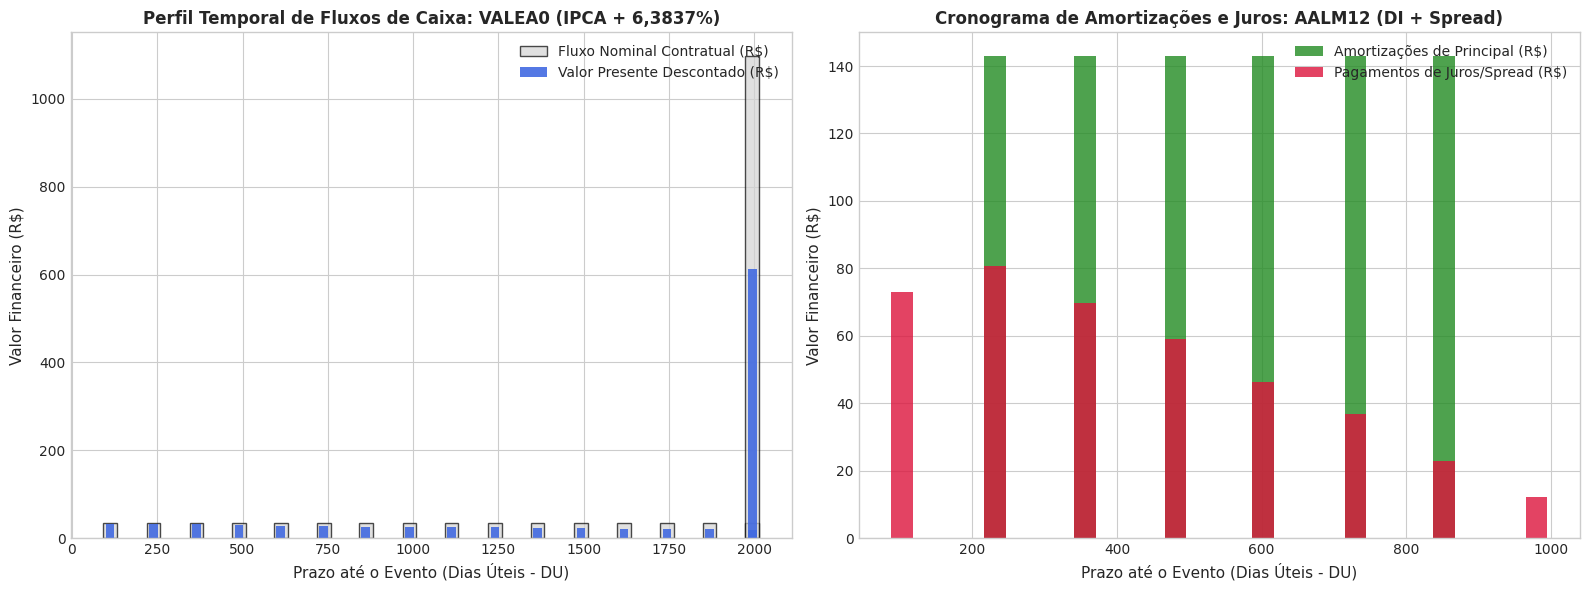

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Decomposição dos fluxos nominais e descontados da VALEA0
axes[0].bar(df_cf_vale['du'], df_cf_vale['fluxo_nominal'], width=40, color='lightgray', edgecolor='black', alpha=0.7, label='Fluxo Nominal Contratual (R$)')
axes[0].bar(df_cf_vale['du'], df_cf_vale['valor_presente'], width=25, color='royalblue', alpha=0.9, label='Valor Presente Descontado (R$)')
axes[0].set_title('Perfil Temporal de Fluxos de Caixa: VALEA0 (IPCA + 6,3837%)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Prazo até o Evento (Dias Úteis - DU)', fontsize=11)
axes[0].set_ylabel('Valor Financeiro (R$)', fontsize=11)
axes[0].legend(loc='upper right')

# Gráfico 2: Cronograma de Amortizações e Juros da AALM12
amort_df = df_cf_aalm[df_cf_aalm['evento'] == 'Amortização']
juros_df = df_cf_aalm[df_cf_aalm['evento'] == 'Juros']

axes[1].bar(amort_df['du'], amort_df['fluxo_nominal'], width=30, color='forestgreen', alpha=0.8, label='Amortizações de Principal (R$)')
axes[1].bar(juros_df['du'], juros_df['fluxo_nominal'], width=30, color='crimson', alpha=0.8, label='Pagamentos de Juros/Spread (R$)')
axes[1].set_title('Cronograma de Amortizações e Juros: AALM12 (DI + Spread)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Prazo até o Evento (Dias Úteis - DU)', fontsize=11)
axes[1].set_ylabel('Valor Financeiro (R$)', fontsize=11)
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()


## 5. Referências Normativas e Bibliográficas

- **ANBIMA – Associação Brasileira das Entidades dos Mercados Financeiro e de Capitais.** *Metodologia ANBIMA de Precificação de Debêntures*. Rio de Janeiro: ANBIMA, 2023. Disponível em: <https://www.anbima.com.br/pt_br/informar/precos-e-indices/precos/debentures.htm>.
- **B3 S.A. – Brasil, Bolsa, Balcão.** *Manual de Apreçamento de Debêntures: Metodologia e Modelos de Apreçamento dos Contratos de Renda Fixa Privada*. São Paulo: B3, 2025. Disponível em: <https://www.b3.com.br/>.
- **Sistema Nacional de Debêntures (SND).** *Portal de Informações de Mercado e Características de Emissões de Debêntures*. Disponível em: <https://www.debentures.com.br/>.
